In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("Dataset.csv")

In [4]:
df['country'].head(10)

0     United States
1            France
2     United States
3            Brazil
4     United States
5    United Kingdom
6     United States
7             India
8           Germany
9             India
Name: country, dtype: object

In [5]:
df['country'].isnull().sum()

np.int64(0)

In [6]:
df['country'].nunique()

86

In [8]:
#Separate multiple countries

country_df = df.assign(
    country=df['country'].str.split(',')
     ).explode('country')

In [9]:
#Remove extra spaces

country_df['country'] = country_df['country'].str.strip()

In [10]:
#country-wise content distribution

country_count = country_df['country'].value_counts()
country_count.head(10)

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64

In [11]:
#Top 10 Countries
top_10_countries = country_count.head(10)
top_10_countries

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64

In [12]:
#Top 5 Countries by Movies
movie_country = country_df[
    country_df['type'] == 'Movie'
]

top_5_movie_countries = (
    movie_country['country'].value_counts().head(5)
)

top_5_movie_countries

country
United States     2395
India              976
United Kingdom     387
Not Given          257
Canada             187
Name: count, dtype: int64

In [13]:
#Top 5 Countries by TV Shows
tv_country = country_df[
    country_df['type'] == 'TV Show'
]

top_5_tv_countries = (
    tv_country['country'].value_counts().head(5)
)

top_5_tv_countries

country
United States     845
Pakistan          350
United Kingdom    251
Japan             172
South Korea       165
Name: count, dtype: int64

In [14]:
#Movies and TV Shows by Country

country_comparison = pd.crosstab(
    country_df['country'],
    country_df['type']
)

country_comparison.head(10)

type,Movie,TV Show
country,,
Argentina,56,20
Australia,61,53
Austria,8,1
Bangladesh,3,0
Belarus,0,1
Belgium,9,9
Brazil,60,28
Bulgaria,5,0
Cambodia,2,0


In [15]:
#Top 10 countries overal

top_countries = country_count.head(10).index
top_country_comparison = country_comparison.loc[top_countries]
top_country_comparison

type,Movie,TV Show
country,,
United States,2395,845
India,976,81
United Kingdom,387,251
Pakistan,71,350
Not Given,257,30
Canada,187,84
Japan,87,172
South Korea,49,165
France,148,65


In [16]:
#Country wise percentage contribution

total_country_records = country_count.sum()

country_percentage = (
    country_count / total_country_records
) * 100

country_percentage.head(10)

country
United States     36.860068
India             12.025028
United Kingdom     7.258248
Pakistan           4.789534
Not Given          3.265074
Canada             3.083049
Japan              2.946530
South Korea        2.434585
France             2.423208
Spain              2.070535
Name: count, dtype: float64

In [17]:
#Country contribution summary table

country_summary = pd.DataFrame({
    'Total Content': country_count,
    'Percentage': country_percentage
})

country_summary = country_summary.sort_values(
    by='Total Content',
    ascending=False
)

country_summary.head(10)

,Total Content,Percentage
country,,
United States,3240,36.860068
India,1057,12.025028
United Kingdom,638,7.258248
Pakistan,421,4.789534
Not Given,287,3.265074
Canada,271,3.083049
Japan,259,2.946530
South Korea,214,2.434585
France,213,2.423208


In [18]:
#Movie contribution by country

movie_country_count = (
    movie_country['country'].value_counts()
)

movie_percentage = (
    movie_country_count / movie_country_count.sum()
) * 100

movie_percentage.head(10)

country
United States     39.095658
India             15.932093
United Kingdom     6.317336
Not Given          4.195233
Canada             3.052563
France             2.415932
Spain              2.105779
Egypt              1.779301
Nigeria            1.567091
Mexico             1.469148
Name: count, dtype: float64

In [19]:
#TV Show contribution by country

tv_country_count = (
    tv_country['country'].value_counts()
)

tv_percentage = (
    tv_country_count / tv_country_count.sum()
) * 100

tv_percentage.head(10)

country
United States     31.719219
Pakistan          13.138138
United Kingdom     9.421922
Japan              6.456456
South Korea        6.193694
Canada             3.153153
India              3.040541
Taiwan             2.665165
France             2.439940
Australia          1.989489
Name: count, dtype: float64

In [20]:
#Movie and TV Show contributions

market_comparison = pd.DataFrame({
    'Movies': movie_country_count,
    'TV Shows': tv_country_count
}).fillna(0)

market_comparison['Total Content'] = (
    market_comparison['Movies'] +
    market_comparison['TV Shows']
)

market_comparison = market_comparison.sort_values(
    by='Total Content',
    ascending=False
)

market_comparison.head(10)

,Movies,TV Shows,Total Content
country,,,
United States,2395.0,845.0,3240.0
India,976.0,81.0,1057.0
United Kingdom,387.0,251.0,638.0
Pakistan,71.0,350.0,421.0
Not Given,257.0,30.0,287.0
Canada,187.0,84.0,271.0
Japan,87.0,172.0,259.0
South Korea,49.0,165.0,214.0
France,148.0,65.0,213.0


In [21]:
#Top 10 countries' combined contribution

top_10_contribution = country_percentage.head(10).sum()

print(
    "Top 10 Countries Contribution:",
    round(top_10_contribution, 2),
    "%"
)

Top 10 Countries Contribution: 77.16 %


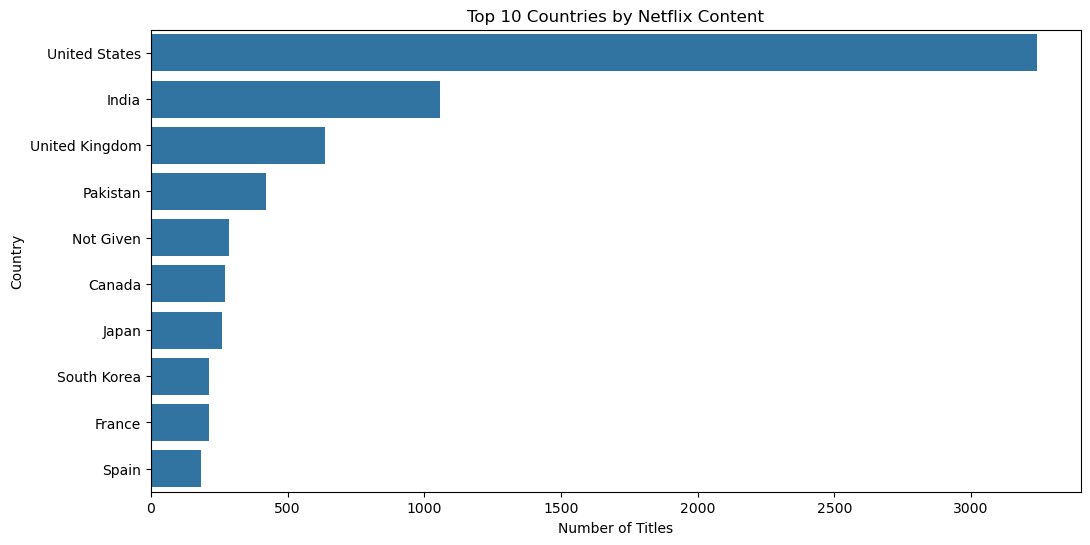

In [22]:
#Top 10 Countries by Content

plt.figure(figsize=(12, 6))
sns.barplot(
    x=top_10_countries.values,
    y=top_10_countries.index
)

plt.title('Top 10 Countries by Netflix Content')
plt.xlabel('Number of Titles')
plt.ylabel('Country')

plt.show()

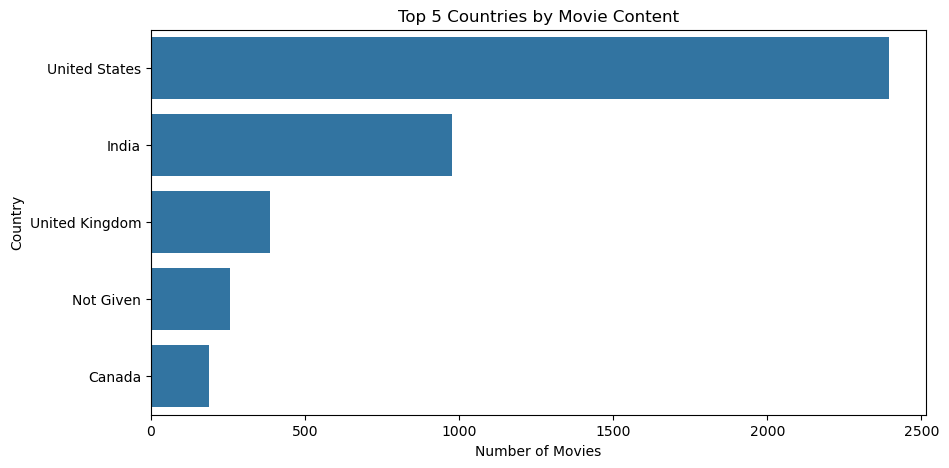

In [23]:
#Top 5 Countries by Movies

plt.figure(figsize=(10, 5))
sns.barplot(
    x=top_5_movie_countries.values,
    y=top_5_movie_countries.index
)

plt.title('Top 5 Countries by Movie Content')
plt.xlabel('Number of Movies')
plt.ylabel('Country')

plt.show()

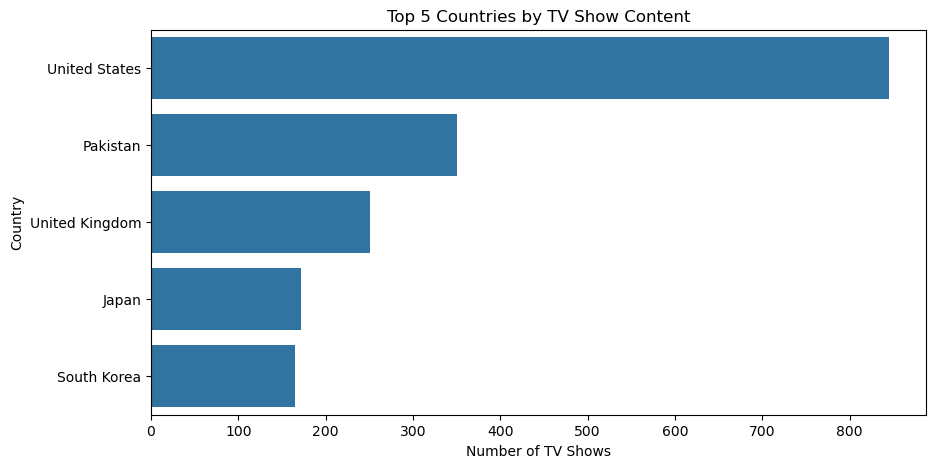

In [24]:
#Top 5 Countries by TV Shows

plt.figure(figsize=(10, 5))
sns.barplot(
    x=top_5_tv_countries.values,
    y=top_5_tv_countries.index
)

plt.title('Top 5 Countries by TV Show Content')
plt.xlabel('Number of TV Shows')
plt.ylabel('Country')

plt.show()

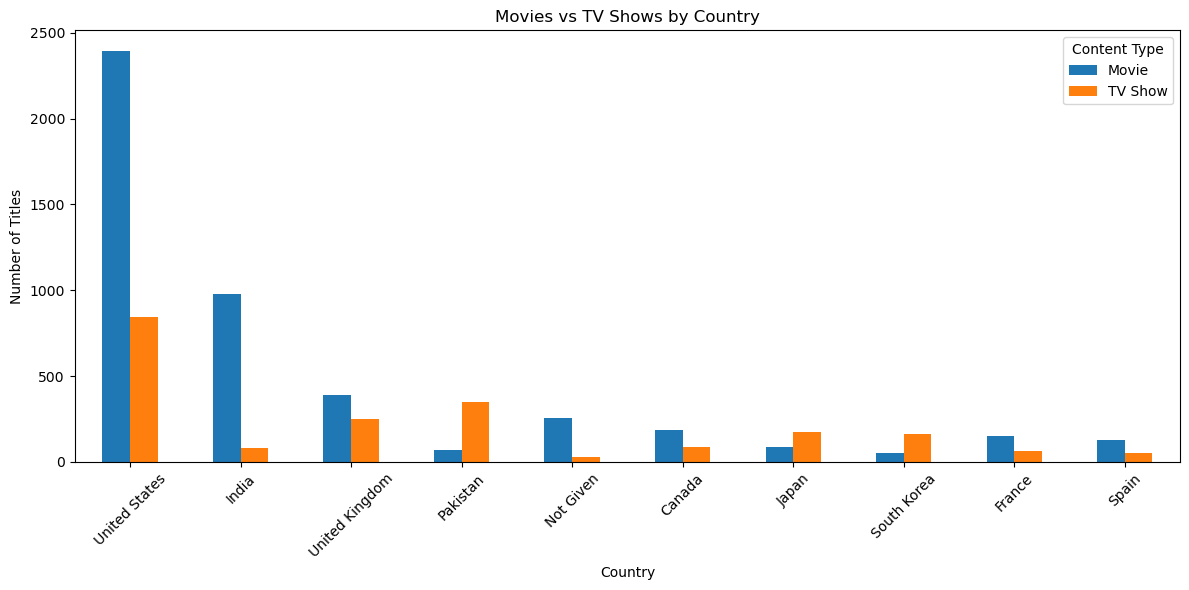

In [25]:
#Movie vs TV Show Comparison

top_country_comparison.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Movies vs TV Shows by Country')
plt.xlabel('Country')
plt.ylabel('Number of Titles')

plt.xticks(rotation=45)
plt.legend(title='Content Type')
plt.tight_layout()

plt.show()

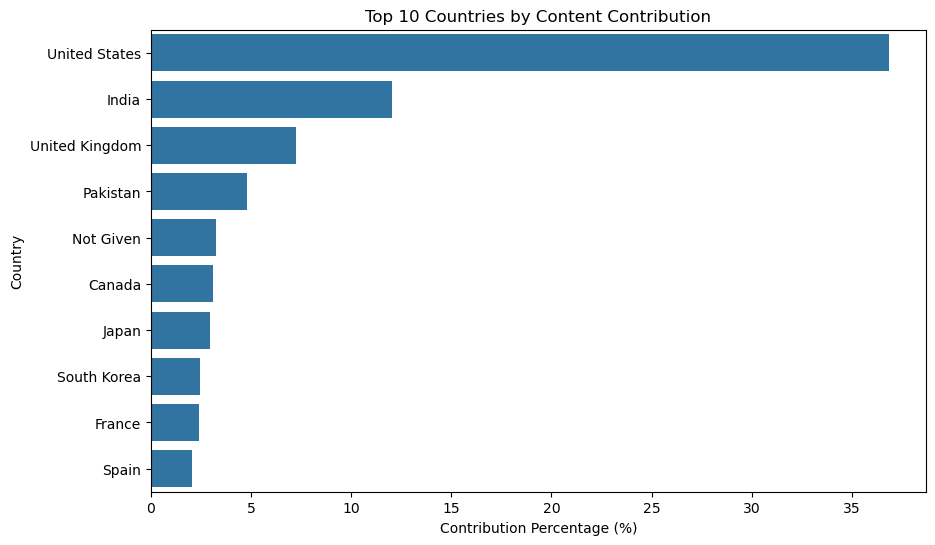

In [26]:
#Country Contribution Percentage

plt.figure(figsize=(10, 6))
top_10_percentage = country_percentage.head(10)
sns.barplot(
    x=top_10_percentage.values,
    y=top_10_percentage.index
)

plt.title('Top 10 Countries by Content Contribution')
plt.xlabel('Contribution Percentage (%)')
plt.ylabel('Country')

plt.show()

In [27]:
#Countries with lower content representation

low_content_countries = market_comparison[
    market_comparison['Total Content'] > 0
].sort_values(
    by='Total Content',
    ascending=True
).head(10)

low_content_countries

,Movies,TV Shows,Total Content
country,,,
Zimbabwe,1.0,0.0,1.0
Senegal,0.0,1.0,1.0
Guatemala,1.0,0.0,1.0
West Germany,1.0,0.0,1.0
Belarus,0.0,1.0,1.0
Cameroon,1.0,0.0,1.0
Cyprus,0.0,1.0,1.0
Greece,1.0,0.0,1.0
Iran,1.0,0.0,1.0


In [28]:
#Movie vs TV Show opportunities

country_mix = market_comparison.copy()

country_mix['Movie Percentage'] = (
    country_mix['Movies'] /
    country_mix['Total Content'] * 100
)

country_mix['TV Show Percentage'] = (
    country_mix['TV Shows'] /
    country_mix['Total Content'] * 100
)

country_mix.head(10)

,Movies,TV Shows,Total Content,Movie Percentage,TV Show Percentage
country,,,,,
United States,2395.0,845.0,3240.0,73.919753,26.080247
India,976.0,81.0,1057.0,92.336802,7.663198
United Kingdom,387.0,251.0,638.0,60.658307,39.341693
Pakistan,71.0,350.0,421.0,16.864608,83.135392
Not Given,257.0,30.0,287.0,89.547038,10.452962
Canada,187.0,84.0,271.0,69.003690,30.996310
Japan,87.0,172.0,259.0,33.590734,66.409266
South Korea,49.0,165.0,214.0,22.897196,77.102804
France,148.0,65.0,213.0,69.483568,30.516432


In [29]:
#Potential expansion opportunities

expansion_opportunities = low_content_countries[
    ['Movies', 'TV Shows', 'Total Content']
].copy()

expansion_opportunities['Content Gap'] = (
    expansion_opportunities['Movies'] -
    expansion_opportunities['TV Shows']
)

expansion_opportunities

,Movies,TV Shows,Total Content,Content Gap
country,,,,
Zimbabwe,1.0,0.0,1.0,1.0
Senegal,0.0,1.0,1.0,-1.0
Guatemala,1.0,0.0,1.0,1.0
West Germany,1.0,0.0,1.0,1.0
Belarus,0.0,1.0,1.0,-1.0
Cameroon,1.0,0.0,1.0,1.0
Cyprus,0.0,1.0,1.0,-1.0
Greece,1.0,0.0,1.0,1.0
Iran,1.0,0.0,1.0,1.0


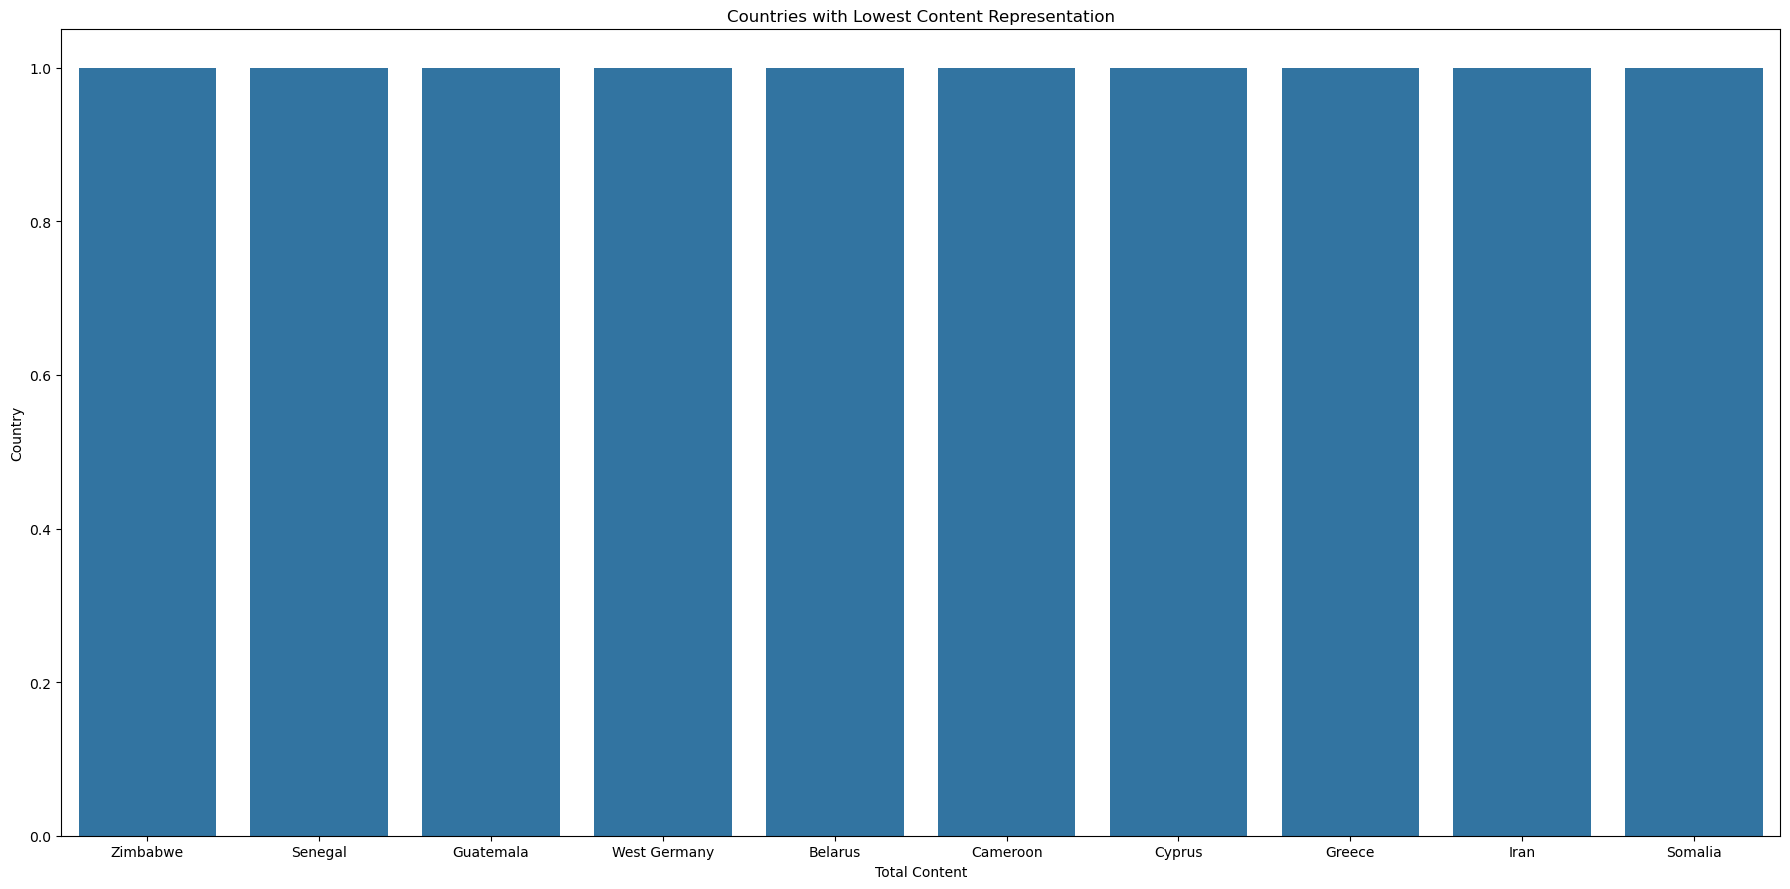

In [32]:
#Visualization for expansion opportunities

plt.figure(figsize=(18, 9))
sns.barplot(
    data=low_content_countries.reset_index(),
    x='country',
    y='Total Content'
)

plt.title('Countries with Lowest Content Representation')
plt.xlabel('Total Content')
plt.ylabel('Country')

plt.tight_layout()
plt.show()